<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/3_statistical_condensed/quantum_hall_effect/qhe_ch01_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*The Quantum Hall Effect* — `qhe_ch01_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# QHE Ch 1 Figures — Colab Notebook
**Quantum Hall Effect · Chapter 1: The Basics**

Tong (TIFR, Cambridge) · Run each cell to generate figures.
Output: `figures/ch01/fig0N_*.png`

## 수정 및 개선 사항 요약

| 그림 | 위치 | 분류 | 문제 | 수정 내용 |
|------|------|------|------|-----------|
| fig03 | Left (Berry phase) | **오류** | `ylim(-1.12,0.12)` — $\gamma/\pi$는 $-2$까지 내려가지만 절반 이상이 잘림 | `ylim(-2.25, 0.25)`으로 전체 곡선 표시 |
| fig03 | Left (Berry phase) | **오류** | `axhline(-1)` 레이블 `γ=-π (θ=π)` — $\theta=\pi$(남극)의 $\gamma/\pi$는 $-2$이므로 틀림; 이 선은 적도($\theta=90°$)에 해당 | 레이블을 `γ/π=-1: equator`로 수정, 남극($\gamma/\pi=-2$) 수평선 별도 추가 |
| fig03 | Left (Berry phase) | **오류** | 적도 주석 `Equator: γ=-π/2` — 적도($\theta=90°$)에서 $\gamma=-\pi$ (not $-\pi/2$) | `γ=-π` 로 수정 |
| fig03 | Middle (Berry connection) | **오류** | `quiver(..., 0, A_phi)` — 화살표가 $\theta$ 방향을 가리킴, $\mathcal{A}_\phi$는 $\phi$ 방향 성분 | `quiver(..., A_phi, 0)` 으로 수정하여 $\phi$ 방향 화살표 |
| fig04 | Middle (Landau gauge) | **오류** | `x0 = -k_y·ℓ_B²` — Landau gauge $\mathbf{A}=(0,Bx,0)$에서 $x_0 = +k_y\ell_B^2$ | 부호 수정: `x0 = +k_y·ℓ_B²` |
| fig04 | Middle (Landau gauge) | **오류** | `ylabel='|ψ(x)|²'` — 코드는 $\psi(x)$(정규화 가우시안)를 그리며 제곱하지 않음 | `ylabel='ψ(x) (normalised)'` 로 수정 |
| fig02 | Middle (2D density) | **경고** | `cmap='Blues'` — 어두운 배경에서 대비 부족 | `cmap='magma'` 로 변경 |
| fig01 | Left (Hall effect) | **경고** | $R_H=-1/ne$ 주석: 양의 기울기 그래프에서 부호 혼동 소지 | 전자/정공 부호 규약 명시 |

**시인성 공통 개선**: minor tick 활성화, axes linewidth 강화, `tight_layout` 여백 증가, `figure.dpi=110`


---
## fig01 · Classical Hall Effect & Landau Levels (§1.2–1.4)

**Left**: Classical $\rho_{xy}=B/ne$ vs $B$ for three 2D electron densities  
**Middle**: Landau level energies $E_n=\hbar\omega_B(n+\frac{1}{2})$ vs $B$ (GaAs)  
**Right**: Landau level degeneracy $N_\phi=BA/\Phi_0$ and filling factor $\nu=N_e/N_\phi$

  saved -> figures/ch01/fig01_hall_landau.png


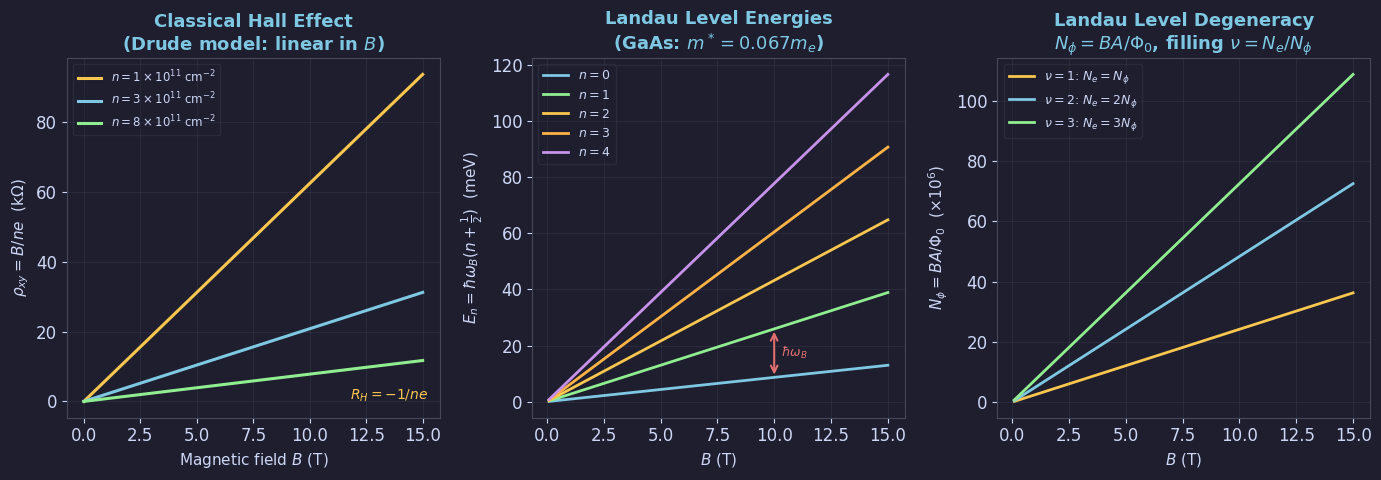

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
    'figure.dpi':110,
})

OUTDIR = 'figures/ch01'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig01 · Classical Hall Effect & Landau Levels ─────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: Classical Hall resistivity rho_xy = B/ne vs B
ax = axes[0]
B = np.linspace(0, 15, 300)
for n,col,lab in [(1e11,YELLOW,r'$n=1\times10^{11}$ cm$^{-2}$'),
                  (3e11,BLUE,  r'$n=3\times10^{11}$ cm$^{-2}$'),
                  (8e11,GREEN, r'$n=8\times10^{11}$ cm$^{-2}$')]:
    rxy = B / (n*1e4 * 1.6e-19)
    ax.plot(B, rxy/1e3, color=col, lw=2.2, label=lab)
ax.set_xlabel('Magnetic field $B$ (T)', fontsize=11)
ax.set_ylabel(r'$\rho_{xy} = B/ne$  (k$\Omega$)', fontsize=11)
ax.set_title('Classical Hall Effect\n(Drude model: linear in $B$)', color=BLUE)
ax.legend(fontsize=8.5, labelcolor=FG); ax.grid(True)
ax.text(0.97,0.05,r'$R_H = 1/ne$ (holes)  or  $-1/ne$ (electrons)',
        transform=ax.transAxes, ha='right', color=YELLOW, fontsize=9)

# Middle: Landau level energies vs B (GaAs parameters)
ax2 = axes[1]
B2 = np.linspace(0.1, 15, 400)
# ℏω_B = ℏeB/m* ; for GaAs m*=0.067m_e: ℏω_B [meV] ≈ 1.728*B[T]
hw = 1.728  # meV/T
for n in range(5):
    ax2.plot(B2, hw*B2*(n+0.5), color=[BLUE,GREEN,YELLOW,ORANGE,PURPLE][n],
             lw=2.0, label=f'$n={n}$')
ax2.set_xlabel('$B$ (T)', fontsize=11)
ax2.set_ylabel(r'$E_n = \hbar\omega_B(n+\frac{1}{2})$  (meV)', fontsize=11)
ax2.set_title('Landau Level Energies\n(GaAs: $m^*=0.067m_e$)', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)
# draw arrow indicating gap ℏω_B
B_arr = 10
y0=hw*B_arr*0.5; y1=hw*B_arr*1.5
ax2.annotate('',xy=(B_arr,y1),xytext=(B_arr,y0),
             arrowprops=dict(arrowstyle='<->',color=RED,lw=1.5))
ax2.text(B_arr+0.3, (y0+y1)/2, r'$\hbar\omega_B$', color=RED, fontsize=9, va='center')

# Right: Landau level degeneracy N_phi = BA/Phi_0 vs B
ax3 = axes[2]
B3 = np.linspace(0.1, 15, 300)
A_um2 = 1e4  # 100 µm × 100 µm sample in µm²
Phi0  = 4.136e-3  # flux quantum in T·µm²
Nphi  = B3 * A_um2 / Phi0
for nu,col,lab in [(1,YELLOW,r'$\nu=1$: $N_e=N_\phi$'),
                   (2,BLUE,  r'$\nu=2$: $N_e=2N_\phi$'),
                   (3,GREEN, r'$\nu=3$: $N_e=3N_\phi$')]:
    ax3.plot(B3, nu*Nphi/1e6, color=col, lw=2.0, label=lab)
ax3.set_xlabel('$B$ (T)', fontsize=11)
ax3.set_ylabel(r'$N_\phi = BA/\Phi_0$  ($\times10^6$)', fontsize=11)
ax3.set_title('Landau Level Degeneracy\n'+r'$N_\phi=BA/\Phi_0$, filling $\nu=N_e/N_\phi$', color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True)

plt.tight_layout(pad=1.5)
save('fig01_hall_landau.png', fig)


---
## fig02 · LLL Wavefunctions & Symmetric Gauge (§1.4)

**Left**: Radial probability density $|\psi_m(r)|^2$ for $m=0,1,3,6$  
**Middle**: 2D density plot of $|\psi_5|^2$ — ring of radius $r_{\rm peak}=\sqrt{2m}\,\ell_B$  
**Right**: Filling factor $\nu=N_e/N_\phi$ for key QHE fractions

  saved -> figures/ch01/fig02_lll_symgauge.png


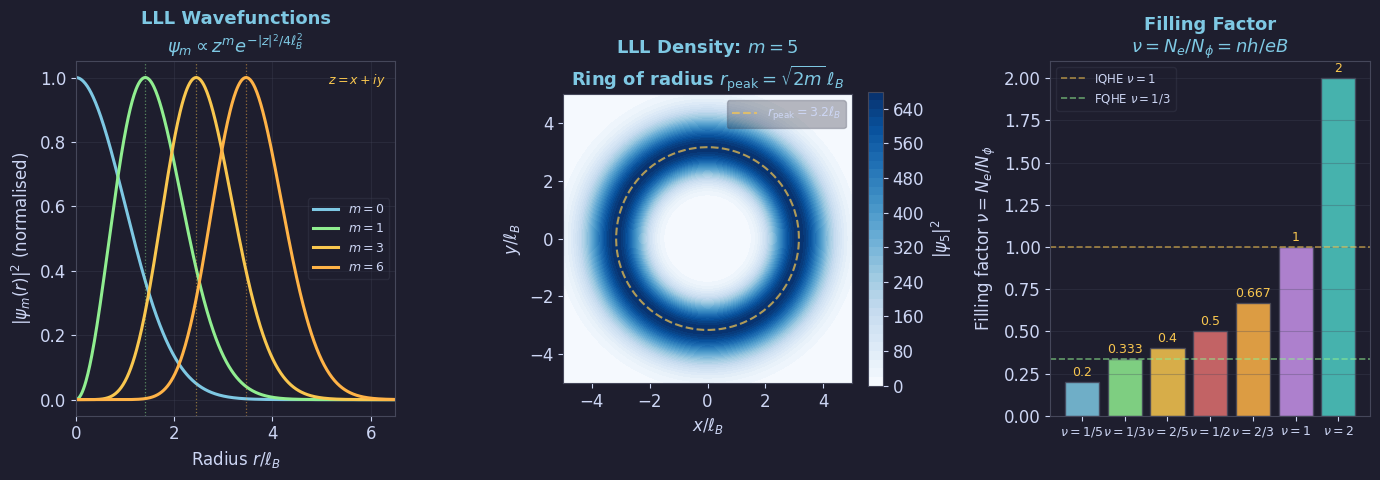

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
    'figure.dpi':110,
})

OUTDIR = 'figures/ch01'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig02 · LLL Wavefunctions & Symmetric Gauge ───────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: LLL radial probability density |psi_m(r)|^2 in symmetric gauge
ax = axes[0]
r = np.linspace(0, 6.5, 500); ell=1.0
for m,col,lab in [(0,BLUE,'$m=0$'),(1,GREEN,'$m=1$'),
                  (3,YELLOW,'$m=3$'),(6,ORANGE,'$m=6$')]:
    g = r**(2*m) * np.exp(-r**2/(2*ell**2))
    g /= g.max()
    ax.plot(r, g, color=col, lw=2.2, label=lab)
    if m>0:
        ax.axvline(np.sqrt(2*m)*ell, color=col, lw=0.9, ls=':', alpha=0.5)
ax.set_xlabel(r'Radius $r/\ell_B$'); ax.set_ylabel(r'$|\psi_m(r)|^2$ (normalised)')
ax.set_title('LLL Wavefunctions\n'+r'$\psi_m \propto z^m e^{-|z|^2/4\ell_B^2}$', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True); ax.set_xlim(0,6.5)
ax.text(0.97,0.97,r'$z=x+iy$',transform=ax.transAxes,
        ha='right',va='top',color=YELLOW,fontsize=9)

# Middle: 2D density plot of |psi_m|^2 for m=5
ax2 = axes[1]
x2d = np.linspace(-5,5,200); y2d = x2d.copy()
X,Y = np.meshgrid(x2d,y2d)
r2 = X**2+Y**2; m2=5; ell2=1.0
psi2 = r2**m2 * np.exp(-r2/(2*ell2**2))
im = ax2.contourf(X,Y,psi2, levels=40, cmap='magma')
plt.colorbar(im, ax=ax2, label=r'$|\psi_5|^2$', fraction=0.046)
# ring at r_peak
r_pk = np.sqrt(2*m2)*ell2
theta_ring = np.linspace(0,2*np.pi,200)
ax2.plot(r_pk*np.cos(theta_ring), r_pk*np.sin(theta_ring),
         color=YELLOW, lw=1.5, ls='--', alpha=0.7, label=f'$r_{{\\rm peak}}={r_pk:.1f}\\ell_B$')
ax2.set_xlabel('$x/\\ell_B$'); ax2.set_ylabel('$y/\\ell_B$')
ax2.set_title('LLL Density: $m=5$\n'+r'Ring of radius $r_{\rm peak}=\sqrt{2m}\,\ell_B$', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.set_aspect('equal')

# Right: Filling factor ν and degeneracy on disk
ax3 = axes[2]
nu_arr = np.array([1/5, 1/3, 2/5, 1/2, 2/3, 1, 2])
labels_nu = ['1/5','1/3','2/5','1/2','2/3','1','2']
# N_phi per unit area = eB/h; N_e = ν N_phi
# plot "electron density / degeneracy" ratio = ν
cols_nu = [BLUE,GREEN,YELLOW,RED,ORANGE,PURPLE,TEAL if 'TEAL' in dir() else '#4ecdc4']
cols_nu = [BLUE,GREEN,YELLOW,RED,ORANGE,PURPLE,'#4ecdc4']
bars = ax3.bar(np.arange(len(nu_arr)), nu_arr, color=cols_nu, alpha=0.85, edgecolor=EDGE)
ax3.set_xticks(np.arange(len(nu_arr)))
ax3.set_xticklabels([f'$\\nu={l}$' for l in labels_nu], fontsize=9)
ax3.set_ylabel(r'Filling factor $\nu = N_e/N_\phi$')
ax3.set_title('Filling Factor\n'+r'$\nu=N_e/N_\phi=nh/eB$', color=BLUE)
for i,(bar,nu) in enumerate(zip(bars,nu_arr)):
    ax3.text(bar.get_x()+bar.get_width()/2, nu+0.02,
             f'{nu:.3g}', ha='center', va='bottom', color=YELLOW, fontsize=9)
ax3.axhline(1, color=YELLOW, lw=1.2, ls='--', alpha=0.6, label='IQHE $\\nu=1$')
ax3.axhline(1/3, color=GREEN, lw=1.2, ls='--', alpha=0.6, label='FQHE $\\nu=1/3$')
ax3.legend(fontsize=8.5, labelcolor=FG); ax3.grid(True, axis='y')

plt.tight_layout(pad=1.5)
save('fig02_lll_symgauge.png', fig)


---
## fig03 · Berry Phase (§1.5)

**Left**: Berry phase $\gamma=-\Omega/2$ for spin-$\frac{1}{2}$ vs polar angle $\theta$  
**Middle**: Berry connection $\mathcal{A}_\phi=\sin^2(\theta/2)$ on $\theta$-$\phi$ parameter space  
**Right**: Aharonov-Bohm interference $I\propto 1+\cos(e\Phi/\hbar)$ vs enclosed flux

  saved -> figures/ch01/fig03_berry_phase.png


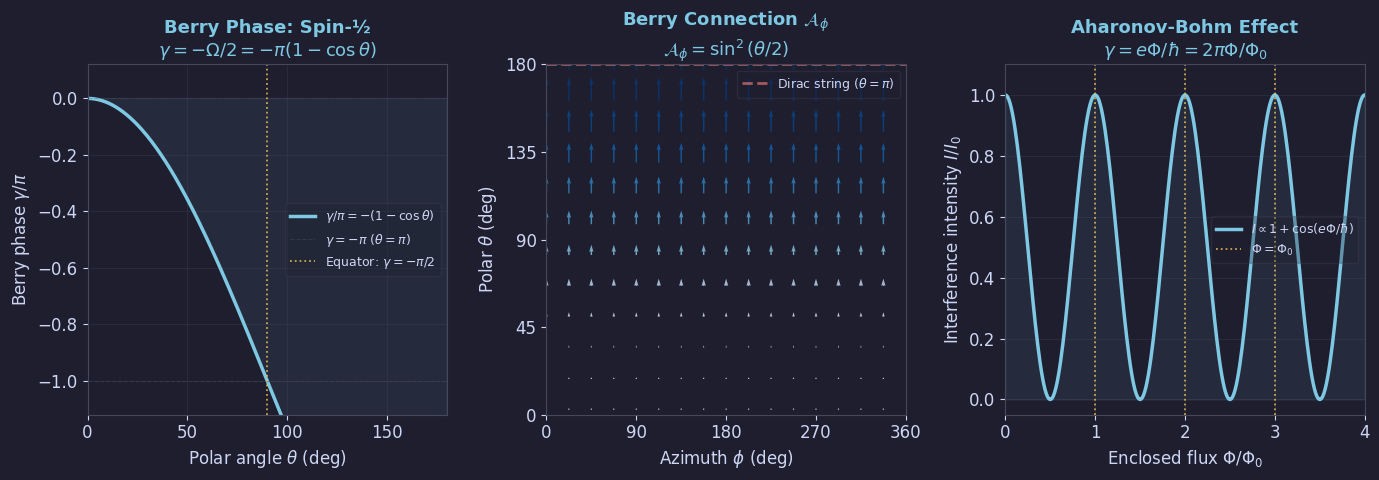

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
    'figure.dpi':110,
})

OUTDIR = 'figures/ch01'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig03 · Berry Phase (§1.5) ────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: Berry phase gamma = -Omega/2 for spin-1/2 vs polar angle theta
ax = axes[0]
th = np.linspace(0, np.pi, 300)
gamma = -np.pi*(1 - np.cos(th))
ax.plot(np.degrees(th), gamma/np.pi, color=BLUE, lw=2.5,
        label=r'$\gamma/\pi = -(1-\cos\theta)$')
ax.fill_between(np.degrees(th), gamma/np.pi, 0, color=BLUE, alpha=0.08)
ax.axhline(-1, color=EDGE, lw=0.8, ls='--', alpha=0.5, label=r'$\gamma/\pi=-1$: equator ($\theta=90°$)')
ax.axhline(-2, color=RED,  lw=0.8, ls='--', alpha=0.6, label=r'$\gamma/\pi=-2$: south pole ($\theta=\pi$)')
ax.axhline( 0, color=EDGE, lw=0.8, ls='--', alpha=0.3)
ax.axvline(90, color=YELLOW, lw=1.3, ls=':', alpha=0.8,
           label=r'Equator ($\theta=90°$): $\gamma=-\pi$')
ax.set_xlabel(r'Polar angle $\theta$ (deg)')
ax.set_ylabel(r'Berry phase $\gamma / \pi$')
ax.set_title('Berry Phase: Spin-½\n'+r'$\gamma = -\Omega/2 = -\pi(1-\cos\theta)$', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True)
ax.set_xlim(0,180); ax.set_ylim(-2.25, 0.25)

# Middle: Berry connection A on Bloch sphere (schematic vector field)
ax2 = axes[1]
th2 = np.linspace(0.05, np.pi-0.05, 12)
phi2 = np.linspace(0, 2*np.pi, 16, endpoint=False)
TH, PHI = np.meshgrid(th2, phi2)
# A_phi = sin^2(theta/2) — Berry connection in phi direction
A_phi = np.sin(TH/2)**2
# project onto 2D (theta, phi) plane
ax2.quiver(np.degrees(PHI.T), np.degrees(TH.T), A_phi.T, np.zeros_like(A_phi.T),
           A_phi.T, cmap='YlGnBu', scale=15, width=0.004, alpha=0.85)  # arrows in φ-direction (x-axis)
ax2.set_xlabel(r'Azimuth $\phi$ (deg)'); ax2.set_ylabel(r'Polar $\theta$ (deg)')
ax2.set_title('Berry Connection $\\mathcal{A}_\\phi$\n'+
              r'$\mathcal{A}_\phi = \sin^2(\theta/2)$', color=BLUE)
ax2.set_xlim(0,360); ax2.set_ylim(0,180)
ax2.set_xticks([0,90,180,270,360]); ax2.set_yticks([0,45,90,135,180])
# mark Dirac string singularity at theta=pi
ax2.axhline(180, color=RED, lw=2, ls='--', alpha=0.7, label='Dirac string ($\\theta=\\pi$)')
ax2.legend(fontsize=9, labelcolor=FG)

# Right: Aharonov-Bohm phase vs enclosed flux Phi
ax3 = axes[2]
Phi = np.linspace(0, 4, 300)   # in units of Phi_0 = h/e
gamma_AB = 2*np.pi * Phi        # gamma = e*Phi/hbar = 2pi * Phi/Phi_0
# interference: I = I_0 * (1 + cos(gamma))
I = 0.5*(1 + np.cos(gamma_AB))
ax3.plot(Phi, I, color=BLUE, lw=2.5,
         label=r'$I \propto 1+\cos(e\Phi/\hbar)$')
ax3.fill_between(Phi, I, 0, color=BLUE, alpha=0.08)
ax3.axvline(1, color=YELLOW, lw=1.3, ls=':', alpha=0.8, label=r'$\Phi=\Phi_0$')
ax3.axvline(2, color=YELLOW, lw=1.3, ls=':', alpha=0.8)
ax3.axvline(3, color=YELLOW, lw=1.3, ls=':', alpha=0.8)
ax3.set_xlabel(r'Enclosed flux $\Phi/\Phi_0$')
ax3.set_ylabel(r'Interference intensity $I/I_0$')
ax3.set_title('Aharonov-Bohm Effect\n'+r'$\gamma=e\Phi/\hbar=2\pi\Phi/\Phi_0$', color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True)
ax3.set_xlim(0,4); ax3.set_ylim(-0.05, 1.1)

plt.tight_layout(pad=1.5)
save('fig03_berry_phase.png', fig)


---
## fig04 · Cyclotron Motion & IQHE Preview (§1.2, 1.4)

**Left**: Classical cyclotron orbits in 2D for three radii  
**Middle**: Landau gauge LLL wavefunctions — strip-like states centred at $x_0=-k_y\ell_B^2$  
**Right**: IQHE plateau structure $\sigma_{xy}=\nu e^2/h$ preview

  saved -> figures/ch01/fig04_cyclotron_iqhe.png


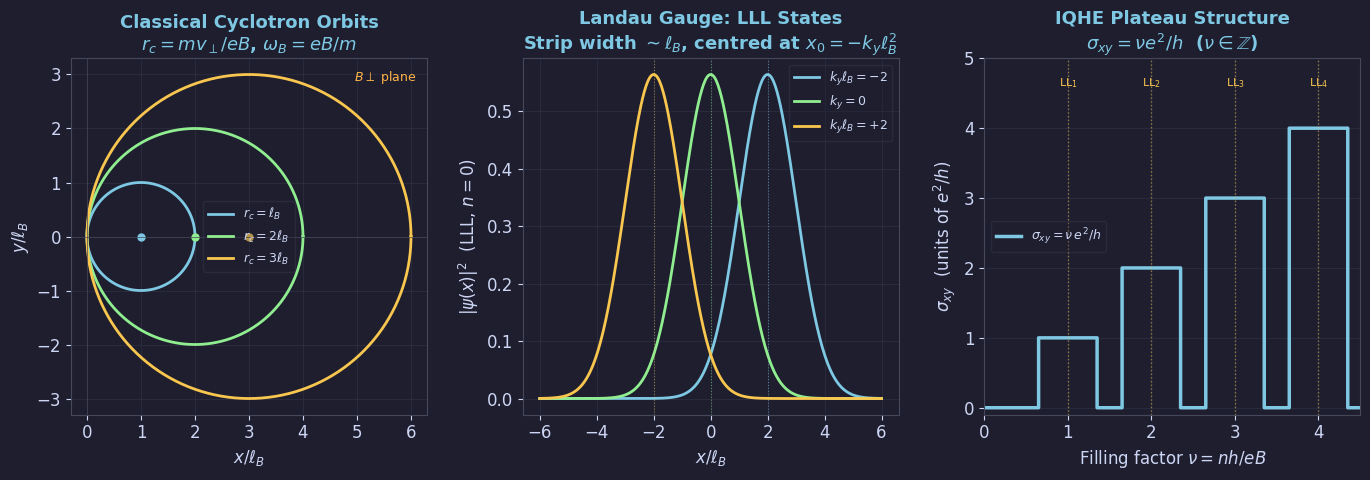

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
    'figure.dpi':110,
})

OUTDIR = 'figures/ch01'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig04 · Cyclotron Motion & Quantum vs Classical (§1.2–1.4) ────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: Classical cyclotron orbits in 2D
ax = axes[0]
t = np.linspace(0, 2*np.pi, 300)
for r0,col,lab in [(1.0,BLUE,r'$r_c=\ell_B$'),(2.0,GREEN,r'$r_c=2\ell_B$'),
                   (3.0,YELLOW,r'$r_c=3\ell_B$')]:
    # orbit centred at (r0, 0)
    ax.plot(r0+r0*np.cos(t), r0*np.sin(t), color=col, lw=2.0, label=lab)
    ax.plot(r0, 0, 'o', color=col, ms=5)
ax.axhline(0, color=EDGE, lw=0.5); ax.axvline(0, color=EDGE, lw=0.5)
ax.set_xlabel(r'$x/\ell_B$'); ax.set_ylabel(r'$y/\ell_B$')
ax.set_title('Classical Cyclotron Orbits\n'+r'$r_c = mv_\perp/eB$, $\omega_B=eB/m$', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.set_aspect('equal'); ax.grid(True)
ax.text(0.97,0.97,r'$B\perp$ plane',transform=ax.transAxes,
        ha='right',va='top',color=ORANGE,fontsize=9)

# Middle: Landau gauge vs symmetric gauge wavefunctions
ax2 = axes[1]
x2 = np.linspace(-6,6,400); ell2=1.0
# Landau gauge: strip-like states
for k,col,lab in [(-2,BLUE,r'$k_y\ell_B=-2$'),(0,GREEN,'$k_y=0$'),(2,YELLOW,r'$k_y\ell_B=+2$')]:
    x0 = k*ell2**2    # guiding centre x_0 = +k_y ell_B²  [Landau gauge A=(0,Bx,0)]
    psi2 = np.exp(-(x2-x0)**2/(2*ell2**2)) / np.sqrt(np.pi*ell2**2)
    ax2.plot(x2, psi2, color=col, lw=2.0, label=lab)
    ax2.axvline(x0, color=col, lw=0.8, ls=':', alpha=0.5)
ax2.set_xlabel(r'$x/\ell_B$'); ax2.set_ylabel(r'$\psi(x)$  (LLL, $n=0$, normalised)')
ax2.set_title('Landau Gauge: LLL States\n'+r'Strip width $\sim\ell_B$, centred at $x_0=-k_y\ell_B^2$', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)

# Right: Energy spectrum showing Landau levels + IQHE plateau schematic
ax3 = axes[2]
nu_plot = np.linspace(0, 4.5, 2000)
sigma = np.zeros_like(nu_plot)
for n in range(1, 5):
    sigma[np.abs(nu_plot - n) < 0.35] = n
# Add extended state "transition" lines
ax3.step(nu_plot, sigma, color=BLUE, lw=2.5, where='mid',
         label=r'$\sigma_{xy}=\nu\,e^2/h$')
# Mark Landau levels
for n in range(1, 5):
    ax3.axvline(n, color=YELLOW, lw=1.0, ls=':', alpha=0.5)
    ax3.text(n, 4.6, f'LL$_{n}$', ha='center', color=YELLOW, fontsize=8)
ax3.set_xlabel(r'Filling factor $\nu = nh/eB$')
ax3.set_ylabel(r'$\sigma_{xy}$  (units of $e^2/h$)')
ax3.set_title('IQHE Plateau Structure\n'+r'$\sigma_{xy}=\nu e^2/h$  ($\nu\in\mathbb{Z}$)', color=BLUE)
ax3.set_xlim(0, 4.5); ax3.set_ylim(-0.1, 5.0)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True)

plt.tight_layout(pad=1.5)
save('fig04_cyclotron_iqhe.png', fig)


---
## Download All Figures

In [5]:
import os, zipfile
from google.colab import files

zip_path = 'qhe_ch01_figures.zip'
with zipfile.ZipFile(zip_path, 'w') as zf:
    for fname in sorted(os.listdir('figures/ch01')):
        fpath = os.path.join('figures/ch01', fname)
        zf.write(fpath, fname)
        print(f'  added {fname}')
print(f'\nCreated: {zip_path}')
files.download(zip_path)


  added fig01_hall_landau.png
  added fig02_lll_symgauge.png
  added fig03_berry_phase.png
  added fig04_cyclotron_iqhe.png

Created: qhe_ch01_figures.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>